In [379]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler, PowerTransformer, OneHotEncoder
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, root_mean_squared_error, r2_score
from sklearn.metrics import mean_absolute_error, cohen_kappa_score
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

#importacion de librerias de arbol de regresion
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.tree import plot_tree

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold





brainrot_df = pd.read_csv("short_form_brain_rot_cognitive_decay.csv")

brainrot_df.head()

,participant_id,age,gender,primary_platform,daily_short_form_hours,avg_clip_duration_sec,swipes_per_minute,scroll_sessions_day,bedtime_scroll_min,total_sleep_hours,multitasking_score,total_screen_time_hours,sustained_attention_span_sec,working_memory_score,task_switch_latency_sec,brain_fog_score,dopamine_burnout_index,attention_retention_pct,cognitive_decay_tier
0,ROT-00001,24,Female,Instagram Reels,2.4,5.1,11.8,9,70,7.8,4.0,5.9,74.1,7.4,11.1,3.6,37.6,49.4,Mild Attentional Strain
1,ROT-00002,48,Female,TikTok,4.0,11.1,5.4,10,90,6.1,2.9,6.8,71.6,6.9,9.6,4.8,34.7,47.7,Mild Attentional Strain
2,ROT-00003,34,Female,Instagram Reels,3.3,17.5,3.4,13,59,6.5,3.3,8.1,93.8,6.6,8.3,4.4,35.5,62.5,Mild Attentional Strain
3,ROT-00004,30,Male,Instagram Reels,3.6,11.8,5.1,7,57,6.9,2.2,7.3,84.5,6.7,8.8,4.4,36.0,56.3,Mild Attentional Strain
4,ROT-00005,19,Female,YouTube Shorts,1.9,17.3,3.5,4,30,7.2,3.5,6.2,110.2,9.3,7.1,3.8,18.0,73.5,Normal / Intact Focus


**SECCIÓN 1: TIPOS DE VARIABLES**


In [227]:
print(f"Total de registros: {brainrot_df.shape[0]:,}")
print(f"Total de columnas: {brainrot_df.shape[1]}")
print(f"Valores vacíos: {brainrot_df.isna().sum().sum()}")
print(f"Filas duplicadas: {brainrot_df.duplicated().sum()}")

display(brainrot_df.head()) #ver los primeros 5 regitros del data frame

Total de registros: 9,000
Total de columnas: 19
Valores vacíos: 0
Filas duplicadas: 0


,participant_id,age,gender,primary_platform,daily_short_form_hours,avg_clip_duration_sec,swipes_per_minute,scroll_sessions_day,bedtime_scroll_min,total_sleep_hours,multitasking_score,total_screen_time_hours,sustained_attention_span_sec,working_memory_score,task_switch_latency_sec,brain_fog_score,dopamine_burnout_index,attention_retention_pct,cognitive_decay_tier
0,ROT-00001,24,Female,Instagram Reels,2.4,5.1,11.8,9,70,7.8,4.0,5.9,74.1,7.4,11.1,3.6,37.6,49.4,Mild Attentional Strain
1,ROT-00002,48,Female,TikTok,4.0,11.1,5.4,10,90,6.1,2.9,6.8,71.6,6.9,9.6,4.8,34.7,47.7,Mild Attentional Strain
2,ROT-00003,34,Female,Instagram Reels,3.3,17.5,3.4,13,59,6.5,3.3,8.1,93.8,6.6,8.3,4.4,35.5,62.5,Mild Attentional Strain
3,ROT-00004,30,Male,Instagram Reels,3.6,11.8,5.1,7,57,6.9,2.2,7.3,84.5,6.7,8.8,4.4,36.0,56.3,Mild Attentional Strain
4,ROT-00005,19,Female,YouTube Shorts,1.9,17.3,3.5,4,30,7.2,3.5,6.2,110.2,9.3,7.1,3.8,18.0,73.5,Normal / Intact Focus


In [228]:
#observar los tipos de datos por cada columna
print(f"Tipos de datos por columna:{brainrot_df.dtypes}")

Tipos de datos por columna:participant_id                      str
age                               int64
gender                              str
primary_platform                    str
daily_short_form_hours          float64
avg_clip_duration_sec           float64
swipes_per_minute               float64
scroll_sessions_day               int64
bedtime_scroll_min                int64
total_sleep_hours               float64
multitasking_score              float64
total_screen_time_hours         float64
sustained_attention_span_sec    float64
working_memory_score            float64
task_switch_latency_sec         float64
brain_fog_score                 float64
dopamine_burnout_index          float64
attention_retention_pct         float64
cognitive_decay_tier                str
dtype: object


In [229]:
#observar cuantas columnas numericas hay y cuantas categoricas
print(f"Cantidad de columnas por tipo \n{brainrot_df.dtypes.value_counts()}")

Cantidad de columnas por tipo 
float64    12
str         4
int64       3
Name: count, dtype: int64


In [230]:
#valores faltantes del dataframe
brainrot_df.isna().sum()

participant_id                  0
age                             0
gender                          0
primary_platform                0
daily_short_form_hours          0
avg_clip_duration_sec           0
swipes_per_minute               0
scroll_sessions_day             0
bedtime_scroll_min              0
total_sleep_hours               0
multitasking_score              0
total_screen_time_hours         0
sustained_attention_span_sec    0
working_memory_score            0
task_switch_latency_sec         0
brain_fog_score                 0
dopamine_burnout_index          0
attention_retention_pct         0
cognitive_decay_tier            0
dtype: int64

In [231]:
#se separaran las columnas numericas y categoricas, para evitar tener tantos tipos de datos

num_cols=brainrot_df.select_dtypes(include= ['int64', 'float64']).columns.tolist() #para columnas numericas
cat_cols=brainrot_df.select_dtypes(include= 'str').columns.tolist() #para columnas categoricas (aunque solo haya un tipo)

#comprobar que las columnas si se guardaron en sus respectivos grupos
print(num_cols)
print(cat_cols)

['age', 'daily_short_form_hours', 'avg_clip_duration_sec', 'swipes_per_minute', 'scroll_sessions_day', 'bedtime_scroll_min', 'total_sleep_hours', 'multitasking_score', 'total_screen_time_hours', 'sustained_attention_span_sec', 'working_memory_score', 'task_switch_latency_sec', 'brain_fog_score', 'dopamine_burnout_index', 'attention_retention_pct']
['participant_id', 'gender', 'primary_platform', 'cognitive_decay_tier']


Cantidad de valores repetidos en cada una de las variables categoricas

In [232]:
brainrot_df['gender'].value_counts()

gender
Male          4395
Female        4338
Non-Binary     267
Name: count, dtype: int64

In [233]:
brainrot_df['primary_platform'].value_counts()

primary_platform
TikTok                3684
Instagram Reels       3044
YouTube Shorts        1609
Snapchat Spotlight     663
Name: count, dtype: int64

In [234]:
brainrot_df['cognitive_decay_tier'].value_counts()

cognitive_decay_tier
Normal / Intact Focus                  3863
Mild Attentional Strain                3677
Severe Focus Fragmentation             1355
Acute Brain Rot / Executive Burnout     105
Name: count, dtype: int64

In [235]:
#listar la cantidad de valores unicos que existen en cada columna
brainrot_df.nunique()

participant_id                  9000
age                               40
gender                             3
primary_platform                   4
daily_short_form_hours           103
avg_clip_duration_sec            227
swipes_per_minute                105
scroll_sessions_day               28
bedtime_scroll_min               181
total_sleep_hours                 61
multitasking_score                90
total_screen_time_hours          125
sustained_attention_span_sec    1253
working_memory_score              84
task_switch_latency_sec          265
brain_fog_score                   91
dopamine_burnout_index           758
attention_retention_pct          864
cognitive_decay_tier               4
dtype: int64

In [236]:
brainrot_df.dtypes.reset_index().set_axis(
    ["Columna", "Tipo de dato"], axis=1
)

,Columna,Tipo de dato
0,participant_id,str
1,age,int64
2,gender,str
3,primary_platform,str
4,daily_short_form_hours,float64
5,avg_clip_duration_sec,float64
6,swipes_per_minute,float64
7,scroll_sessions_day,int64
8,bedtime_scroll_min,int64
9,total_sleep_hours,float64


**SECCIÓN 2: ESTADÍSTICA DESCRIPTIVA**

In [237]:
#estadisticas descriptivas de las variables numericas
brainrot_df.describe()

,age,daily_short_form_hours,avg_clip_duration_sec,swipes_per_minute,scroll_sessions_day,bedtime_scroll_min,total_sleep_hours,multitasking_score,total_screen_time_hours,sustained_attention_span_sec,working_memory_score,task_switch_latency_sec,brain_fog_score,dopamine_burnout_index,attention_retention_pct
count,9000.000000,9000.000000,9000.000000,9000.000000,9000.000000,9000.000000,9000.00000,9000.000000,9000.000000,9000.000000,9000.000000,9000.000000,9000.000000,9000.000000,9000.000000
mean,28.697111,3.203222,11.499200,6.482189,8.999889,59.217667,7.12780,3.341967,6.956444,84.859000,7.321578,9.407611,3.739322,32.945567,56.570989
std,9.499582,1.905133,4.584142,3.766278,5.549773,36.631353,0.93072,1.944690,2.034408,31.790705,1.063906,4.166082,2.164392,15.005315,21.197044
min,16.000000,0.300000,3.000000,2.100000,1.000000,0.000000,3.50000,1.000000,2.900000,8.000000,1.000000,2.000000,1.000000,5.000000,5.300000
25%,21.000000,1.800000,8.200000,4.100000,5.000000,33.000000,6.50000,1.700000,5.500000,67.875000,6.800000,6.600000,2.000000,21.700000,45.275000
50%,27.000000,2.800000,11.400000,5.300000,8.000000,53.000000,7.20000,3.100000,6.600000,91.700000,7.500000,8.500000,3.300000,30.500000,61.100000
75%,35.000000,4.200000,14.500000,7.300000,12.000000,79.000000,7.80000,4.500000,8.100000,108.900000,8.000000,11.200000,5.000000,41.500000,72.600000
max,55.000000,10.500000,28.800000,20.000000,28.000000,180.000000,9.50000,10.000000,15.500000,153.500000,10.000000,32.000000,10.000000,98.500000,100.000000


In [238]:
#estadisticas descriptivas de las variables categoricas
brainrot_df.describe(include='str')

,participant_id,gender,primary_platform,cognitive_decay_tier
count,9000,9000,9000,9000
unique,9000,3,4,4
top,ROT-00001,Male,TikTok,Normal / Intact Focus
freq,1,4395,3684,3863


In [239]:
#moda (valor mas repetido) por cada columna
for col in brainrot_df:
    moda = brainrot_df[col].mode()
    print(f"{col}: {moda[0] if not moda.empty else 'N/A'}")


participant_id: ROT-00001
age: 25
gender: Male
primary_platform: TikTok
daily_short_form_hours: 1.7
avg_clip_duration_sec: 3.0
swipes_per_minute: 20.0
scroll_sessions_day: 7
bedtime_scroll_min: 0
total_sleep_hours: 7.4
multitasking_score: 1.0
total_screen_time_hours: 6.1
sustained_attention_span_sec: 8.0
working_memory_score: 7.7
task_switch_latency_sec: 8.1
brain_fog_score: 1.0
dopamine_burnout_index: 25.5
attention_retention_pct: 5.3
cognitive_decay_tier: Normal / Intact Focus


In [240]:
#ver asimetria de las variables numericas
brainrot_df.skew(numeric_only=True)

age                             0.755168
daily_short_form_hours          1.087867
avg_clip_duration_sec           0.235562
swipes_per_minute               2.058780
scroll_sessions_day             0.942037
bedtime_scroll_min              0.897777
total_sleep_hours              -0.358515
multitasking_score              0.807660
total_screen_time_hours         0.888626
sustained_attention_span_sec   -0.839444
working_memory_score           -1.444254
task_switch_latency_sec         1.718067
brain_fog_score                 0.884155
dopamine_burnout_index          0.881754
attention_retention_pct        -0.840258
dtype: float64

In [241]:
#ver curtosis de las variables numericas
brainrot_df.kurt(numeric_only=True)

age                            -0.222941
daily_short_form_hours          1.307482
avg_clip_duration_sec          -0.306249
swipes_per_minute               4.237463
scroll_sessions_day             0.851637
bedtime_scroll_min              0.771244
total_sleep_hours               0.217503
multitasking_score              0.289385
total_screen_time_hours         0.990310
sustained_attention_span_sec    0.035509
working_memory_score            4.345703
task_switch_latency_sec         4.811128
brain_fog_score                 0.313350
dopamine_burnout_index          0.791148
attention_retention_pct         0.037054
dtype: float64

**SECCIÓN 3: DETECCIÓN DE VALORES NULOS, DUPLICADOS Y ATIPICOS**

In [242]:
#valores faltantes del dataframe
brainrot_df.isnull().sum()



participant_id                  0
age                             0
gender                          0
primary_platform                0
daily_short_form_hours          0
avg_clip_duration_sec           0
swipes_per_minute               0
scroll_sessions_day             0
bedtime_scroll_min              0
total_sleep_hours               0
multitasking_score              0
total_screen_time_hours         0
sustained_attention_span_sec    0
working_memory_score            0
task_switch_latency_sec         0
brain_fog_score                 0
dopamine_burnout_index          0
attention_retention_pct         0
cognitive_decay_tier            0
dtype: int64

In [243]:
#total de valores faltantes
print(f"total de valores faltantes: {brainrot_df.isnull().sum().sum()}")

total de valores faltantes: 0


In [244]:
#valores duplicados en el dataframe
print(f"total de valores duplicados: {brainrot_df.duplicated().sum()}")

#NOTA: cuando hablamos de duplicados nos referimos un mismo registro entero (fila)
#      apareciendo mas de una vez, no a datos repetidos

total de valores duplicados: 0


In [245]:
#valores atipicos de cuantas horas diarias se pasan viendo videos cortos

percentile_25 = brainrot_df["daily_short_form_hours"].quantile(0.25)
percentile_75 = brainrot_df["daily_short_form_hours"].quantile(0.75)

iqr = percentile_75 - percentile_25

upper_limit = percentile_75 + 1.5 * iqr
lower_limit = percentile_25 - 1.5 * iqr


IQR_outliers = brainrot_df[(brainrot_df["daily_short_form_hours"] < lower_limit) | (brainrot_df["daily_short_form_hours"] > upper_limit)]

IQR_outliers[["participant_id", "daily_short_form_hours"]].head(10)


,participant_id,daily_short_form_hours
30,ROT-00031,8.5
46,ROT-00047,8.9
240,ROT-00241,9.5
306,ROT-00307,9.4
325,ROT-00326,9.5
517,ROT-00518,10.4
557,ROT-00558,9.6
584,ROT-00585,8.0
656,ROT-00657,8.3
693,ROT-00694,10.0


In [246]:
#registros con duracion en segundos promedio atipida
percentile_25 = brainrot_df["avg_clip_duration_sec"].quantile(0.25)
percentile_75 = brainrot_df["avg_clip_duration_sec"].quantile(0.75)

iqr = percentile_75 - percentile_25

upper_limit = percentile_75 + 1.5 * iqr
lower_limit = percentile_25 - 1.5 * iqr


IQR_outliers = brainrot_df[(brainrot_df["avg_clip_duration_sec"] < lower_limit) | (brainrot_df["avg_clip_duration_sec"] > upper_limit)]

IQR_outliers[["participant_id", "avg_clip_duration_sec"]].head(10)

,participant_id,avg_clip_duration_sec
823,ROT-00824,28.5
955,ROT-00956,24.1
1308,ROT-01309,24.1
1632,ROT-01633,24.9
1717,ROT-01718,25.8
1974,ROT-01975,24.1
2064,ROT-02065,25.6
2252,ROT-02253,24.2
2655,ROT-02656,24.1
2767,ROT-02768,25.2


In [247]:
#calculo de valores atipicos de cuantas veces deslizan los usuarios por minuto
percentile_25 = brainrot_df["swipes_per_minute"].quantile(0.25)
percentile_75 = brainrot_df["swipes_per_minute"].quantile(0.75)

iqr = percentile_75 - percentile_25

upper_limit = percentile_75 + 1.5 * iqr
lower_limit = percentile_25 - 1.5 * iqr


IQR_outliers = brainrot_df[(brainrot_df["swipes_per_minute"] < lower_limit) | (brainrot_df["swipes_per_minute"] > upper_limit)]

IQR_outliers[["participant_id", "swipes_per_minute"]].head(10)

,participant_id,swipes_per_minute
7,ROT-00008,20.0
35,ROT-00036,20.0
66,ROT-00067,14.3
71,ROT-00072,13.3
77,ROT-00078,20.0
108,ROT-00109,20.0
127,ROT-00128,20.0
132,ROT-00133,17.6
140,ROT-00141,18.2
141,ROT-00142,16.2


In [248]:
#calculo de valores atipicos de cuantas sesiones de doomscroll tienen los usuarios al dia
percentile_25 = brainrot_df["scroll_sessions_day"].quantile(0.25)
percentile_75 = brainrot_df["scroll_sessions_day"].quantile(0.75)

iqr = percentile_75 - percentile_25

upper_limit = percentile_75 + 1.5 * iqr
lower_limit = percentile_25 - 1.5 * iqr


IQR_outliers = brainrot_df[(brainrot_df["scroll_sessions_day"] < lower_limit) | (brainrot_df["scroll_sessions_day"] > upper_limit)]

IQR_outliers[["participant_id", "scroll_sessions_day"]].head(10)

,participant_id,scroll_sessions_day
24,ROT-00025,25
29,ROT-00030,23
30,ROT-00031,24
46,ROT-00047,25
185,ROT-00186,25
236,ROT-00237,25
240,ROT-00241,26
301,ROT-00302,23
306,ROT-00307,28
325,ROT-00326,26


In [249]:
#calculo de valores atipicos de la capacidad de retener información 
# temporalmente en la mente y manipularla para resolver problemas, 
# seguir instrucciones o comprender textos
percentile_25 = brainrot_df["working_memory_score"].quantile(0.25)
percentile_75 = brainrot_df["working_memory_score"].quantile(0.75)

iqr = percentile_75 - percentile_25

upper_limit = percentile_75 + 1.5 * iqr
lower_limit = percentile_25 - 1.5 * iqr


IQR_outliers = brainrot_df[(brainrot_df["working_memory_score"] < lower_limit) | (brainrot_df["working_memory_score"] > upper_limit)]

IQR_outliers[["participant_id", "working_memory_score"]].head(10)


,participant_id,working_memory_score
140,ROT-00141,4.5
158,ROT-00159,4.3
185,ROT-00186,4.8
236,ROT-00237,4.3
240,ROT-00241,1.0
363,ROT-00364,4.7
364,ROT-00365,4.7
392,ROT-00393,1.8
405,ROT-00406,2.8
476,ROT-00477,3.7


In [250]:
def detectar_outliers(datos, columna):

    Q1 = datos[columna].quantile(0.25)
    Q3 = datos[columna].quantile(0.75)

    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = datos[
        (datos[columna] < limite_inferior) |
        (datos[columna] > limite_superior)
    ]

    return outliers, limite_inferior, limite_superior

**Detectar valores atípicos**

Para detectarlos utilizaremos el método IQR (rango intercuartílico).

In [251]:
for columna in num_cols:

    if columna == "participant_id":
        continue

    outliers, inferior, superior = detectar_outliers(brainrot_df, columna)

    print("\nVariable:", columna)
    print("Cantidad de outliers:", len(outliers))
    print("Límite inferior:", round(inferior, 2))
    print("Límite superior:", round(superior, 2))


Variable: age
Cantidad de outliers: 0
Límite inferior: 0.0
Límite superior: 56.0

Variable: daily_short_form_hours
Cantidad de outliers: 244
Límite inferior: -1.8
Límite superior: 7.8

Variable: avg_clip_duration_sec
Cantidad de outliers: 41
Límite inferior: -1.25
Límite superior: 23.95

Variable: swipes_per_minute
Cantidad de outliers: 726
Límite inferior: -0.7
Límite superior: 12.1

Variable: scroll_sessions_day
Cantidad de outliers: 242
Límite inferior: -5.5
Límite superior: 22.5

Variable: bedtime_scroll_min
Cantidad de outliers: 237
Límite inferior: -36.0
Límite superior: 148.0

Variable: total_sleep_hours
Cantidad de outliers: 79
Límite inferior: 4.55
Límite superior: 9.75

Variable: multitasking_score
Cantidad de outliers: 116
Límite inferior: -2.5
Límite superior: 8.7

Variable: total_screen_time_hours
Cantidad de outliers: 216
Límite inferior: 1.6
Límite superior: 12.0

Variable: sustained_attention_span_sec
Cantidad de outliers: 0
Límite inferior: 6.34
Límite superior: 170.4

**SECCIÓN 4: GRAFICAR LOS DATOS**

Histogramas

Cuantas perosnas se encuentran en cada de uno de los niveles deterioro congitivo 

C:\Users\krlba\AppData\Local\Temp\ipykernel_27736\1258339319.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='cognitive_decay_tier', data=brainrot_df, order=order, palette='viridis')


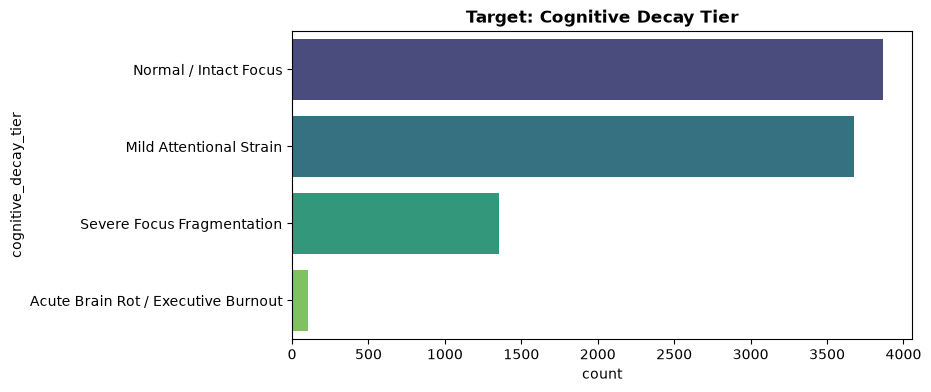

In [252]:
order = brainrot_df['cognitive_decay_tier'].value_counts().index
plt.figure(figsize=(8,4))
sns.countplot(y='cognitive_decay_tier', data=brainrot_df, order=order, palette='viridis')
plt.title('Target: Cognitive Decay Tier',fontweight='bold'); plt.show()

interpretacion: de nuestors 9000 sujetos de estudio, podemos encontrar un  numero 3863 usuarios con un nivel de deterioro normal, o no preocupante, siendo este el grupo mas grande de la clasificacion, seguido de esto, se encuentra el grupo de fatiga atencional, con una diferencia de aproximadamente 200 usuarios.

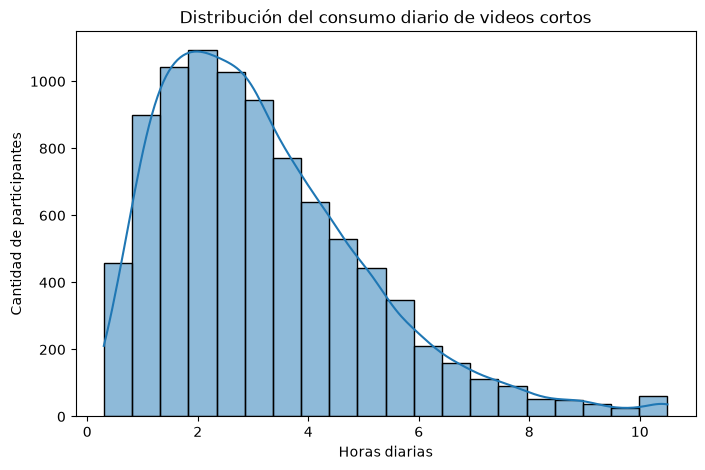

In [253]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=brainrot_df,
    x="daily_short_form_hours",
    bins=20,
    kde=True
)

plt.title("Distribución del consumo diario de videos cortos")
plt.xlabel("Horas diarias")
plt.ylabel("Cantidad de participantes")

plt.show()

histogramas de otras variables

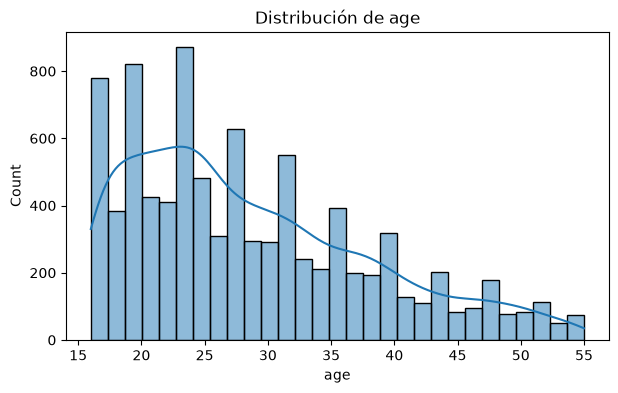

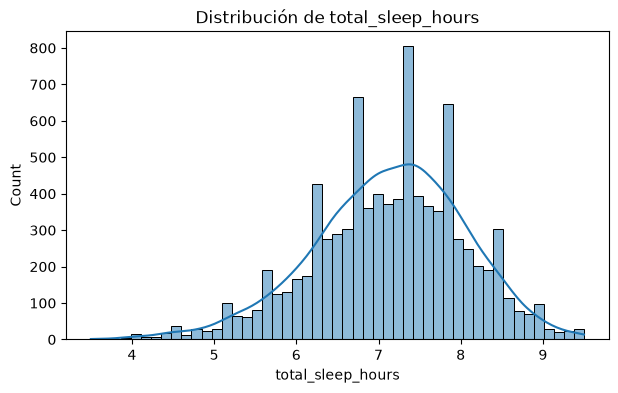

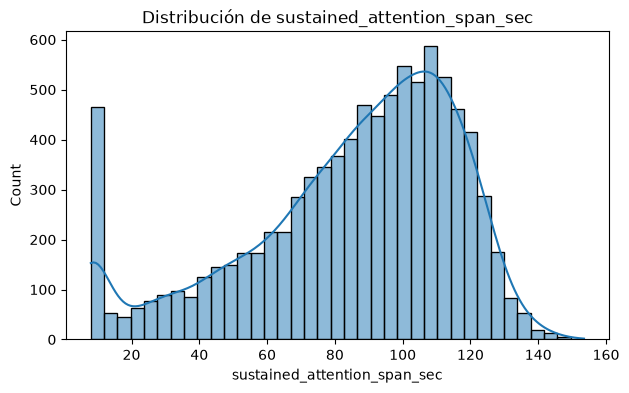

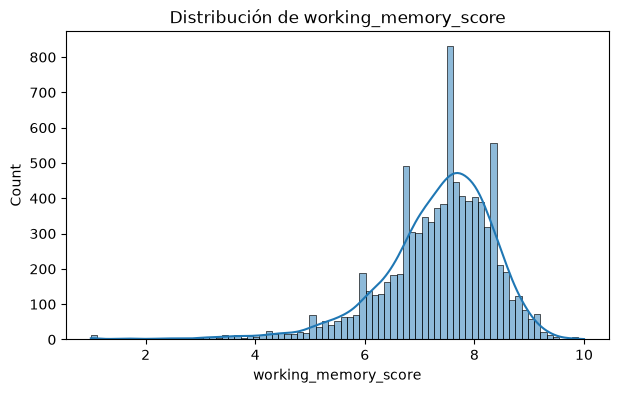

In [254]:
variables = [
    "age",
    "total_sleep_hours",
    "sustained_attention_span_sec",
    "working_memory_score"
]

for columna in variables:

    plt.figure(figsize=(7,4))

    sns.histplot(data=brainrot_df, x=columna, kde=True)

    plt.title(f"Distribución de {columna}")

    plt.show()

Diagramas de caja (Boxplots)

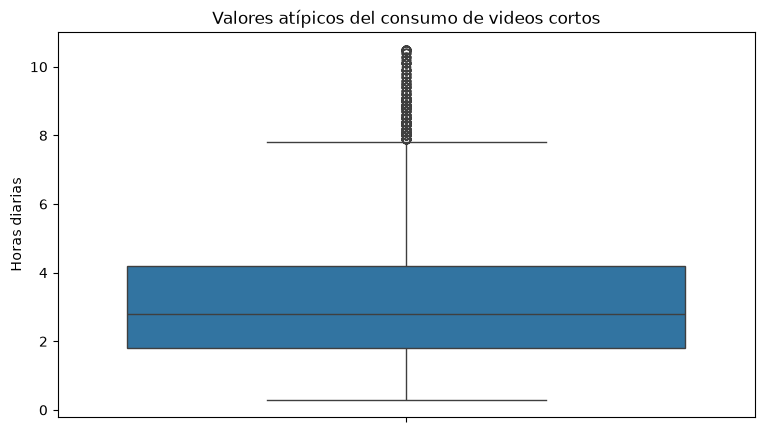

In [255]:
plt.figure(figsize=(9,5))

sns.boxplot(
    data=brainrot_df,
    y="daily_short_form_hours"
)

plt.title("Valores atípicos del consumo de videos cortos")
plt.ylabel("Horas diarias")

plt.show()

Boxplot de otras variables

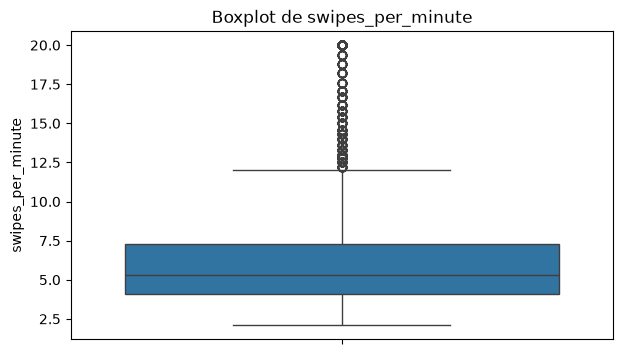

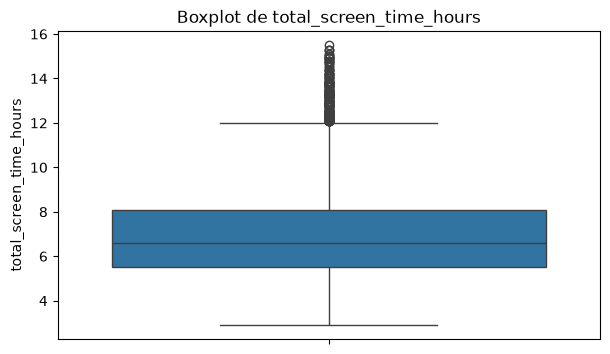

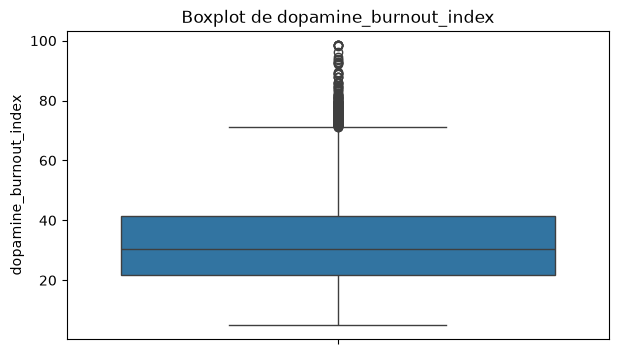

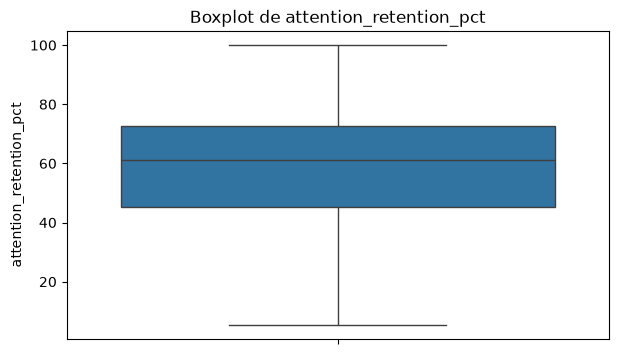

In [256]:
variables = [
    "swipes_per_minute",
    "total_screen_time_hours",
    "dopamine_burnout_index",
    "attention_retention_pct"
]

for columna in variables:

    plt.figure(figsize=(7,4))

    sns.boxplot(data=brainrot_df, y=columna)

    plt.title(f"Boxplot de {columna}")

    plt.show()

A continuacion se observan multiples box plots que muestras la comparacion de distintas columnas con el nivel de deterioro cognitivo de los usuarios, esto para conocer si los usuarios ccon un deterioro alto pasan mas horas viendo videos cortos

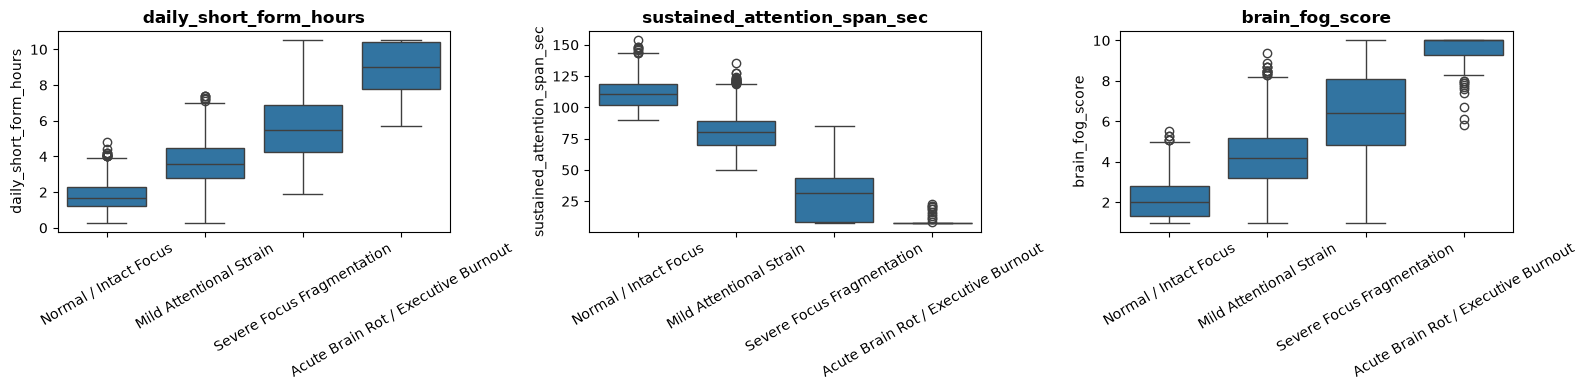

In [257]:
fig, ax = plt.subplots(1, 3, figsize=(16,4))
for a, c in zip(ax, ['daily_short_form_hours','sustained_attention_span_sec','brain_fog_score']):
    sns.boxplot(x='cognitive_decay_tier', y=c, data=brainrot_df, order=order, ax=a)
    a.set_xlabel(''); a.tick_params(axis='x', rotation=30); a.set_title(c,fontweight='bold')
plt.tight_layout(); plt.show()

Gráficas de barras

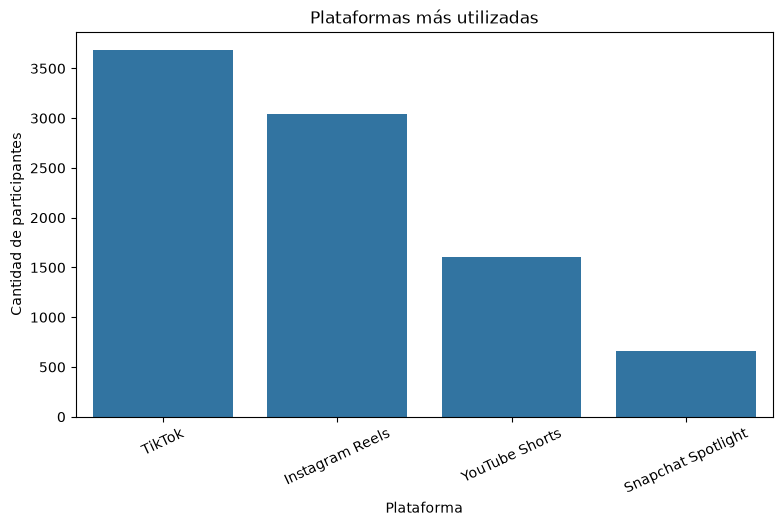

In [258]:
plt.figure(figsize=(9,5))

sns.countplot(
    data=brainrot_df,
    x="primary_platform",
    order=brainrot_df["primary_platform"].value_counts().index
)

plt.title("Plataformas más utilizadas")
plt.xlabel("Plataforma")
plt.ylabel("Cantidad de participantes")

plt.xticks(rotation=25)

plt.show()

Mapa de calor

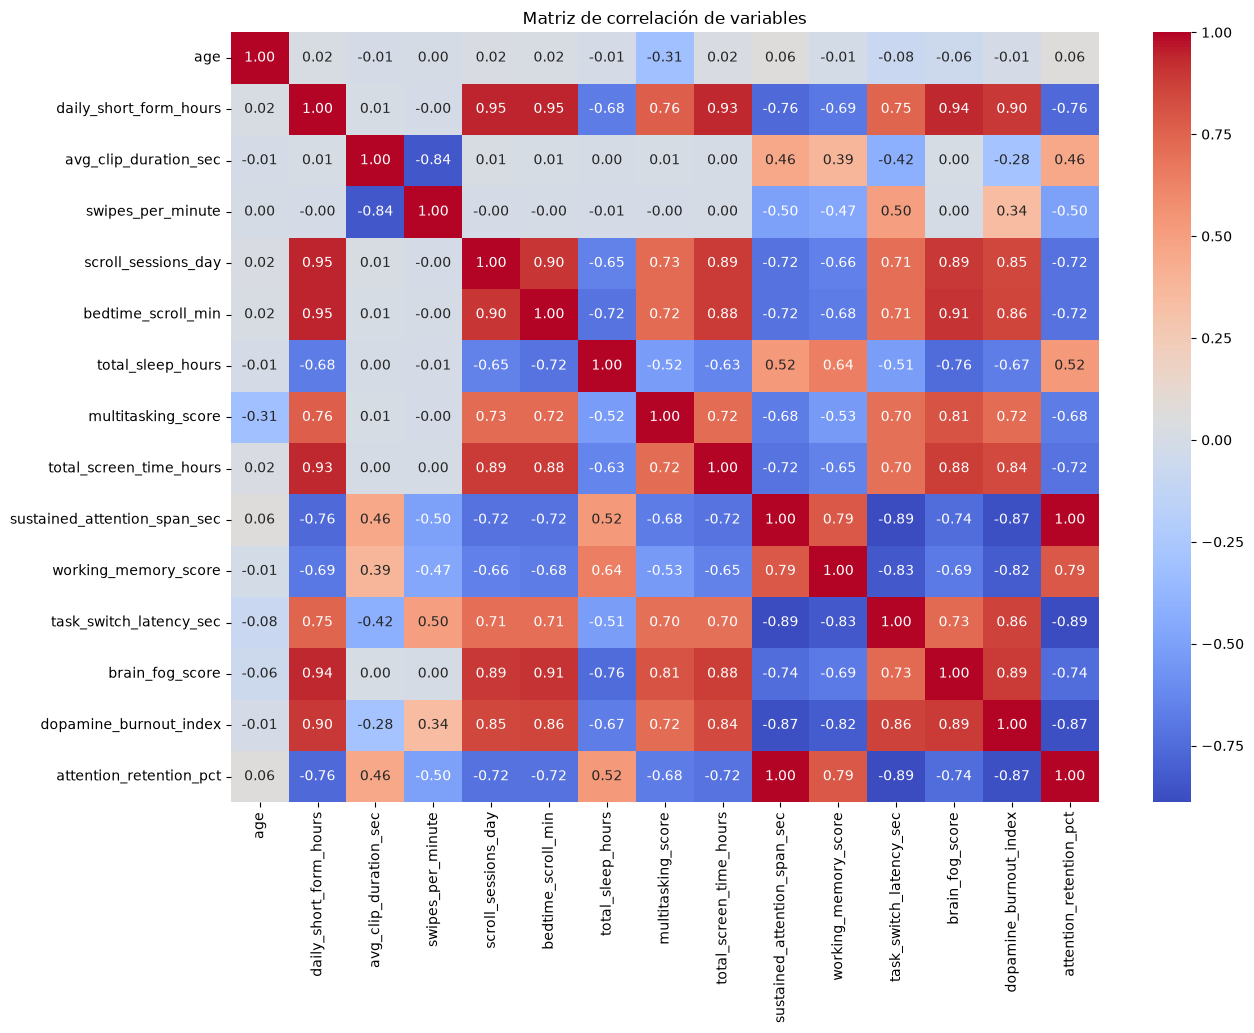

In [259]:
correlaciones = brainrot_df[num_cols].drop(
    columns=["participant_id"],
    errors="ignore"
).corr()

plt.figure(figsize=(14,10))

sns.heatmap(
    correlaciones,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Matriz de correlación de variables")

plt.show()

**Iterpretacion de graficas**

mientras más tiempo en pantalla haya y menos horas de sueño, la atencion de estos usuarios sera debil y habrá mas niebla cerebral.

**SECCIÓN 5: TRATAMIENTO DE LOS DATOS FALTANTES**

En este caso no tenemos datos nulos asi que nos saltamos este paso

**SECIÓN 6: NOMRALIZACIÓN Y TRANSFORMACIÓN DE LOS DATOS**

Normalización con MinMaxScaler

In [260]:
df_minmax = brainrot_df.copy()

columnas_escalado = [
    col for col in num_cols
    if col != "participant_id"
]

scaler = MinMaxScaler()
df_minmax[columnas_escalado] = scaler.fit_transform(
    df_minmax[columnas_escalado]
)

display(df_minmax.head())

,participant_id,age,gender,primary_platform,daily_short_form_hours,avg_clip_duration_sec,swipes_per_minute,scroll_sessions_day,bedtime_scroll_min,total_sleep_hours,multitasking_score,total_screen_time_hours,sustained_attention_span_sec,working_memory_score,task_switch_latency_sec,brain_fog_score,dopamine_burnout_index,attention_retention_pct,cognitive_decay_tier
0,ROT-00001,0.205128,Female,Instagram Reels,0.205882,0.081395,0.541899,0.296296,0.388889,0.716667,0.333333,0.238095,0.454296,0.711111,0.303333,0.288889,0.348663,0.465681,Mild Attentional Strain
1,ROT-00002,0.820513,Female,TikTok,0.362745,0.313953,0.184358,0.333333,0.500000,0.433333,0.211111,0.309524,0.437113,0.655556,0.253333,0.422222,0.317647,0.447730,Mild Attentional Strain
2,ROT-00003,0.461538,Female,Instagram Reels,0.294118,0.562016,0.072626,0.444444,0.327778,0.500000,0.255556,0.412698,0.589691,0.622222,0.210000,0.377778,0.326203,0.604013,Mild Attentional Strain
3,ROT-00004,0.358974,Male,Instagram Reels,0.323529,0.341085,0.167598,0.222222,0.316667,0.566667,0.133333,0.349206,0.525773,0.633333,0.226667,0.377778,0.331551,0.538543,Mild Attentional Strain
4,ROT-00005,0.076923,Female,YouTube Shorts,0.156863,0.554264,0.078212,0.111111,0.166667,0.616667,0.277778,0.261905,0.702405,0.922222,0.170000,0.311111,0.139037,0.720169,Normal / Intact Focus


Escalamiento con StandardScaler

In [261]:
df_standard = brainrot_df.copy()
scaler_standard = StandardScaler()

df_standard[columnas_escalado] = scaler_standard.fit_transform(
    df_standard[columnas_escalado]
)

display(df_standard.head())

,participant_id,age,gender,primary_platform,daily_short_form_hours,avg_clip_duration_sec,swipes_per_minute,scroll_sessions_day,bedtime_scroll_min,total_sleep_hours,multitasking_score,total_screen_time_hours,sustained_attention_span_sec,working_memory_score,task_switch_latency_sec,brain_fog_score,dopamine_burnout_index,attention_retention_pct,cognitive_decay_tier
0,ROT-00001,-0.494482,Female,Instagram Reels,-0.421633,-1.396020,1.412032,0.000020,0.294363,0.722277,0.338393,-0.519317,-0.338451,0.073716,0.406253,-0.064374,0.310203,-0.338320,Mild Attentional Strain
1,ROT-00002,2.032085,Female,TikTok,0.418250,-0.087088,-0.287352,0.180218,0.840374,-1.104368,-0.227281,-0.076904,-0.417095,-0.396277,0.046182,0.490085,0.116927,-0.418524,Mild Attentional Strain
2,ROT-00003,0.558254,Female,Instagram Reels,0.050801,1.309107,-0.818410,0.720810,-0.005942,-0.674569,-0.021581,0.562139,0.281261,-0.678272,-0.265879,0.305266,0.170245,0.279725,Mild Attentional Strain
3,ROT-00004,0.137160,Male,Instagram Reels,0.208279,0.065621,-0.367011,-0.360375,-0.060543,-0.244770,-0.587256,0.168882,-0.011293,-0.584274,-0.145855,0.305266,0.203568,-0.012785,Mild Attentional Strain
4,ROT-00005,-1.020850,Female,YouTube Shorts,-0.684097,1.265476,-0.791857,-0.900968,-0.797658,0.077579,0.081269,-0.371846,0.797164,1.859687,-0.553935,0.028036,-0.996074,0.798694,Normal / Intact Focus


Transformación de variables con Yeo-Johnson

In [262]:
df_yeo = brainrot_df.copy()
columnas_transformacion = [
    "daily_short_form_hours",
    "swipes_per_minute",
    "dopamine_burnout_index",
    "task_switch_latency_sec"
]
yeo = PowerTransformer(
    method="yeo-johnson",
    standardize=False
)

df_yeo[columnas_transformacion] = yeo.fit_transform(
    df_yeo[columnas_transformacion]
)

display(df_yeo.head())

,participant_id,age,gender,primary_platform,daily_short_form_hours,avg_clip_duration_sec,swipes_per_minute,scroll_sessions_day,bedtime_scroll_min,total_sleep_hours,multitasking_score,total_screen_time_hours,sustained_attention_span_sec,working_memory_score,task_switch_latency_sec,brain_fog_score,dopamine_burnout_index,attention_retention_pct,cognitive_decay_tier
0,ROT-00001,24,Female,Instagram Reels,1.225228,5.1,0.937985,9,70,7.8,4.0,5.9,74.1,7.4,1.804123,3.6,5.673340,49.4,Mild Attentional Strain
1,ROT-00002,48,Female,TikTok,1.611951,11.1,0.856056,10,90,6.1,2.9,6.8,71.6,6.9,1.736248,4.8,5.496850,47.7,Mild Attentional Strain
2,ROT-00003,34,Female,Instagram Reels,1.460679,17.5,0.782399,13,59,6.5,3.3,8.1,93.8,6.6,1.666674,4.4,5.546614,62.5,Mild Attentional Strain
3,ROT-00004,30,Male,Instagram Reels,1.528315,11.8,0.848056,7,57,6.9,2.2,7.3,84.5,6.7,1.694822,4.4,5.577289,56.3,Mild Attentional Strain
4,ROT-00005,19,Female,YouTube Shorts,1.065810,17.3,0.787618,4,30,7.2,3.5,6.2,110.2,9.3,1.590443,3.8,4.180009,73.5,Normal / Intact Focus


Comparar sus distribuciones originales y transformadas

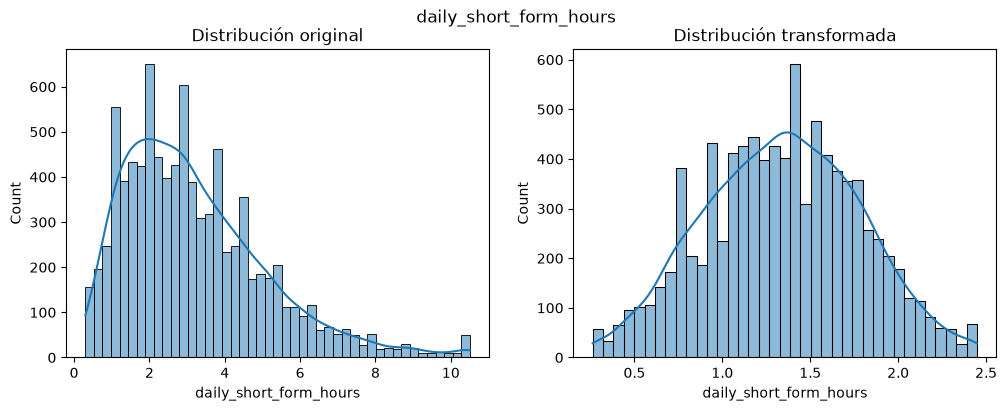

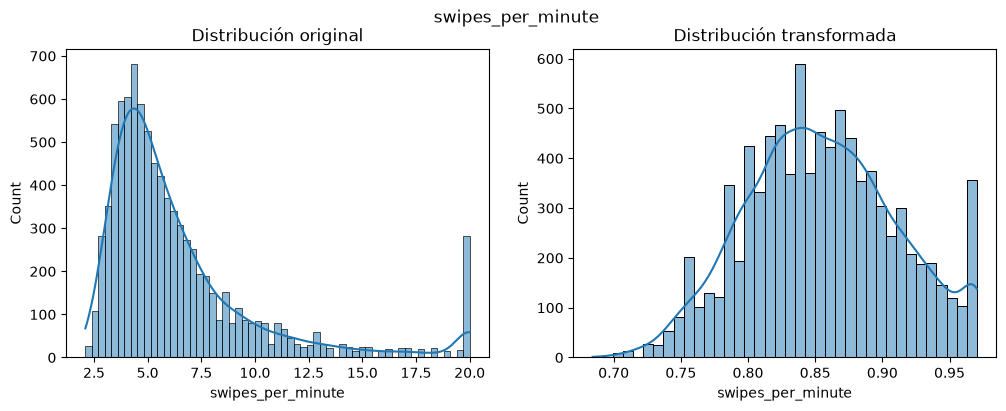

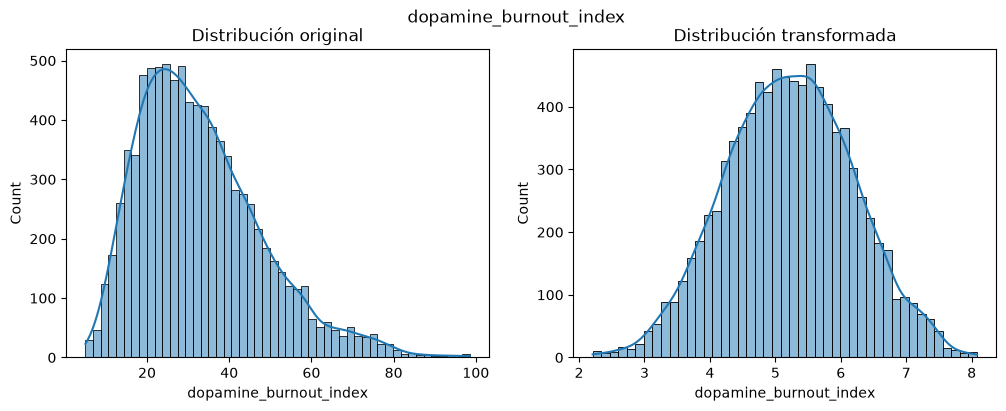

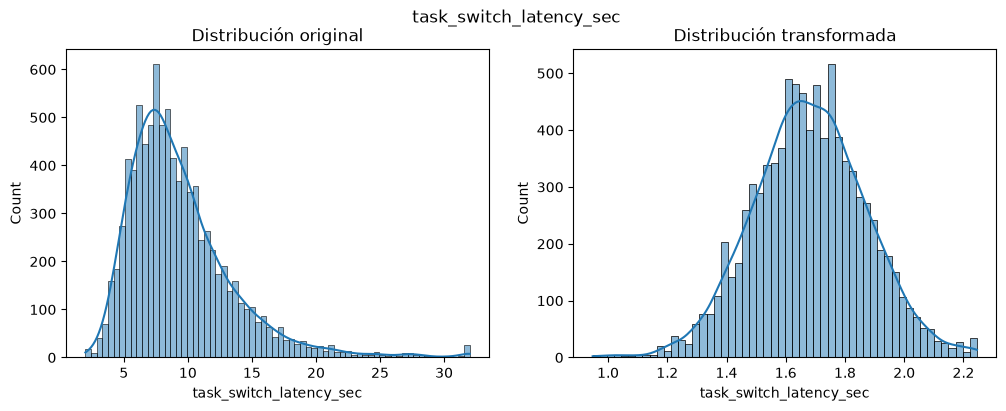

In [263]:
for columna in columnas_transformacion:

    fig, axes = plt.subplots(1, 2, figsize=(12,4))

    sns.histplot(brainrot_df[columna], kde=True, ax=axes[0])
    axes[0].set_title("Distribución original")

    sns.histplot(df_yeo[columna], kde=True, ax=axes[1])
    axes[1].set_title("Distribución transformada")

    plt.suptitle(columna)
    plt.show()

**Preparar y guardar los datos**

- Guardar el dataset limpio

- datos normalizados

- datos transformados

In [264]:
df_limpio = brainrot_df.copy()
df_limpio.to_csv(
    "dataset_limpio.csv",
    index=False
)

print("Dataset limpio guardado correctamente")

Dataset limpio guardado correctamente


In [265]:
df_minmax.to_csv(
    "dataset_normalizado.csv",
    index=False
)

In [266]:
df_standard.to_csv(
    "dataset_estandarizado.csv",
    index=False
)

In [267]:
df_yeo.to_csv(
    "dataset_transformado_yeojohnson.csv",
    index=False
)

#**APLICACION DEL MODELO DE MACHINE LEARNING**

**Preparación de los datos**

In [413]:
y=brainrot_df['cognitive_decay_tier'] # <- como variable oobjetivo

X=brainrot_df.drop(['age','sustained_attention_span_sec', 'gender','cognitive_decay_tier', 'participant_id', 'task_switch_latency_sec','bedtime_scroll_min'
, 'attention_retention_pct','scroll_sessions_day', 'dopamine_burnout_index','total_screen_time_hours', 'total_sleep_hours', 'brain_fog_score'], axis=1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)

print("características para clasificar:", list(X.columns))
print("distribución de clases de entrenamiento:\n", y_train.value_counts())

(7200, 6) (1800, 6)
características para clasificar: ['primary_platform', 'daily_short_form_hours', 'avg_clip_duration_sec', 'swipes_per_minute', 'multitasking_score', 'working_memory_score']
distribución de clases de entrenamiento:
 cognitive_decay_tier
Normal / Intact Focus                  3090
Mild Attentional Strain                2942
Severe Focus Fragmentation             1084
Acute Brain Rot / Executive Burnout      84
Name: count, dtype: int64


In [414]:
#Pipeline
#PARA VARIABLES NUMERICAS
num_pipeline = make_pipeline(SimpleImputer(strategy='median'), MinMaxScaler())
#PARA VARIABLES CATEGORICAS
cat_pipeline = make_pipeline(SimpleImputer(strategy='most_frequent'), OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))

#UNE PREPROCESAMIENTOS
preprocessing_class = ColumnTransformer([
    ('num', num_pipeline, make_column_selector(dtype_include=np.number)), #detecta TODAS columnas numericas                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                     , make_column_selector(dtype_include=np.number)),
    ('cat', cat_pipeline, make_column_selector(dtype_include=object))])   #detecta TODAS columnas categoricas

**MODELOS DE ARBOL DE DECISIÓN RANDOM FOREST**

 El árbol no trata el target como una categoría, sino como un valor numérico que intenta predecir minimizando el error. Al dividir los datos, buscará umbrales en las variables predictoras que mejor separen los valores ordinales del target. 

In [415]:
# Creamos el pipeline con el clasificador DecisionTreeClassifier
dt_classifier = make_pipeline(
    preprocessing_class,
    DecisionTreeClassifier(max_depth=5, random_state=42))# Limitamos la profundidad para evitar sobreajuste
# Entrenamos el modelo
dt_classifier.fit(X_train, y_train)

# Predicciones
y_pred = dt_classifier.predict(X_test)


rf_classifier = make_pipeline(
    preprocessing_class,
    RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
)
rf_classifier.fit(X_train, y_train)
y_pred_rf = rf_classifier.predict(X_test)



qwk = cohen_kappa_score(y_test, y_pred_rf, weights='quadratic')

# Evaluación
print(f"Quadratic Weighted Kappa (QWK): {qwk:.4f}")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nReporte de Clasificación:\n", classification_report(y_test, y_pred))
print("\nMatriz de confusión:\n", confusion_matrix(y_test, y_pred))

Quadratic Weighted Kappa (QWK): 0.6369
Accuracy: 0.82

Reporte de Clasificación:
                                      precision    recall  f1-score   support

Acute Brain Rot / Executive Burnout       0.80      0.38      0.52        21
            Mild Attentional Strain       0.78      0.82      0.80       735
              Normal / Intact Focus       0.89      0.86      0.88       773
         Severe Focus Fragmentation       0.75      0.76      0.75       271

                           accuracy                           0.82      1800
                          macro avg       0.80      0.70      0.73      1800
                       weighted avg       0.82      0.82      0.82      1800


Matriz de confusión:
 [[  8   0   0  13]
 [  0 600  79  56]
 [  0 110 663   0]
 [  2  64   0 205]]


In [374]:
arbol = dt_classifier.named_steps['decisiontreeclassifier']
columnas_procesadas = dt_classifier.named_steps['columntransformer'].get_feature_names_out()

print("Columnas procesadas:", len(columnas_procesadas))
print("Importancias:", len(arbol.feature_importances_))

Columnas procesadas: 8
Importancias: 8


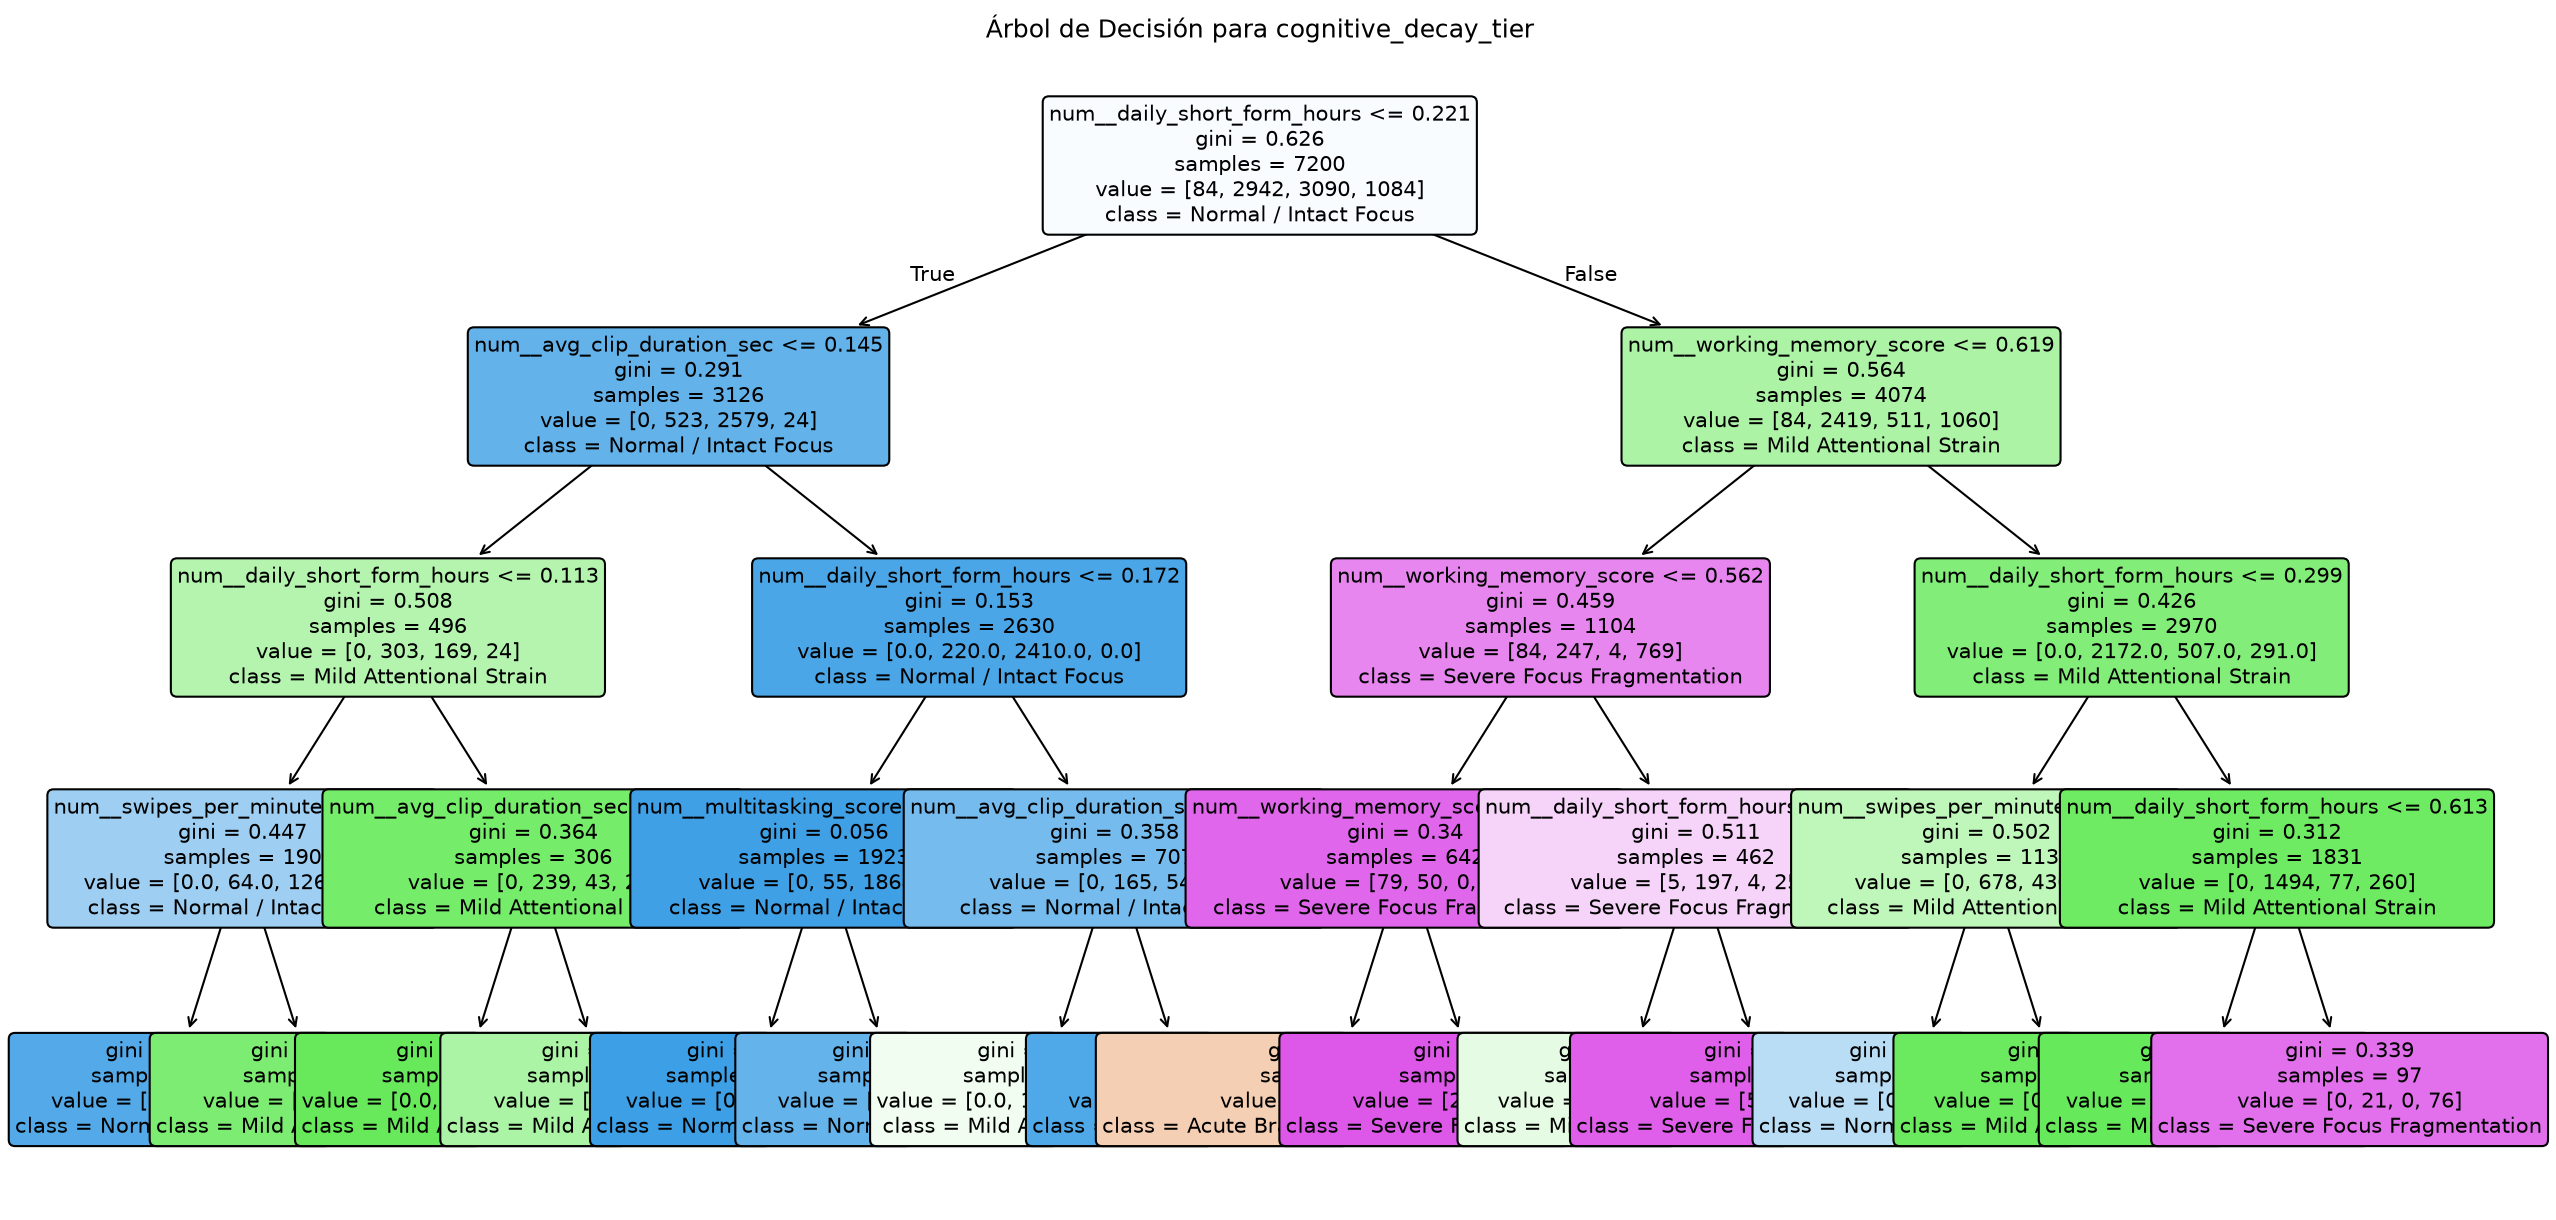

In [416]:
# obtención del árbol de decisión entrenado
plt.figure(figsize=(20, 10), dpi=150)
plot_tree(
    arbol,
    feature_names=columnas_procesadas,
    class_names=dt_classifier.classes_,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Árbol de Decisión para cognitive_decay_tier")
plt.show()

In [417]:
df_importancias = pd.DataFrame({
    'Característica': columnas_procesadas,
    'Importancia': arbol.feature_importances_
}).sort_values(by='Importancia', ascending=False)

df_importancias['Característica'] = (
    df_importancias['Característica']
    .str.replace('num__', '', regex=False)
    .str.replace('cat__', '', regex=False)
)
print(df_importancias)

                        Característica  Importancia
0               daily_short_form_hours     0.596844
4                 working_memory_score     0.225754
1                avg_clip_duration_sec     0.117014
2                    swipes_per_minute     0.058191
3                   multitasking_score     0.002197
5  primary_platform_Snapchat Spotlight     0.000000
6              primary_platform_TikTok     0.000000
7      primary_platform_YouTube Shorts     0.000000


C:\Users\krlba\AppData\Local\Temp\ipykernel_27736\322151690.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_importancias, x='Importancia', y='Característica', palette='viridis')


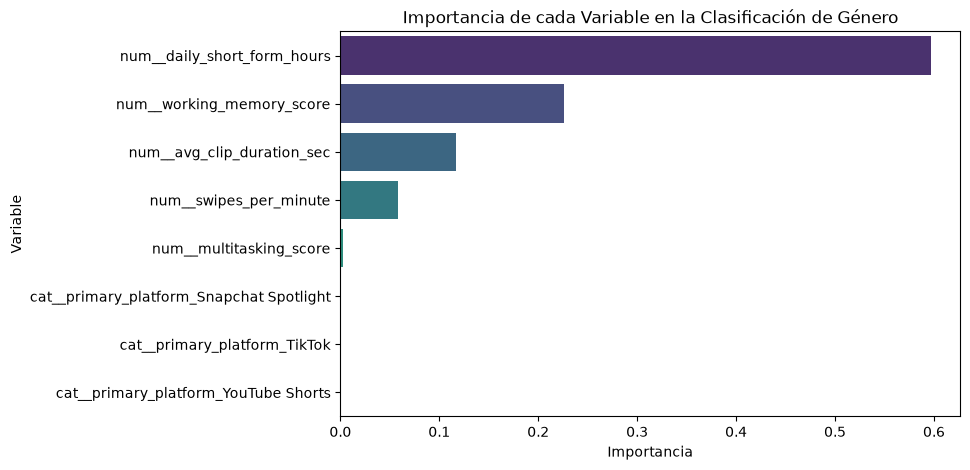

In [418]:
# extraer cuales son las columnas con mas importancia de las variables del árbol entrenado
importancias = arbol.feature_importances_

# subdata frame con estos datos
df_importancias = pd.DataFrame({
    'Característica': columnas_procesadas,
    'Importancia': importancias
}).sort_values(by='Importancia', ascending=False)

# graficar
plt.figure(figsize=(8, 5))
sns.barplot(data=df_importancias, x='Importancia', y='Característica', palette='viridis')
plt.title('Importancia de cada Variable en la Clasificación de Género')
plt.ylabel('Variable')
plt.show()